In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

from my_utils import *

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

from ana_functions import *

In [2]:
def rotate_array(l,x):
    return np.concatenate((l[-x:],l[:-x]),axis=0)

In [46]:


period = 1/150e6

itime_len = 24
ftime_len = 72



from itertools import groupby

def longest_runs(s):
    runs = [(bit, sum(1 for _ in group)) for bit, group in groupby(s)]

    # Ignore clusters touching the start or end
    runs = runs[1:-1]

    max_zeros = max((length for bit, length in runs if bit == '0'), default=0)
    max_ones  = max((length for bit, length in runs if bit == '1'), default=0)

    return max_zeros, max_ones






def process_channel(df,chan,**kwargs):
    
    # the output object
    output = {}

    
    
    plot = kwargs.get("plot",False)
    
    ##################################################
    ##                data selection                ##
    ##################################################


    df_a = df[ (df["chan"] == chan) & (df["falling"] == 0) ]



    ctime_a = np.array(df_a["coarse"])

    itime_a = np.array( [ pop_count(x[0:itime_len]) for x in df_a["fine"] ])

    tdl_a = [ x[itime_len:itime_len+ftime_len][::-1] for x in df_a["fine"] ]

    itime_expected = np.array(df_a["itime"])
    errors = np.where(itime_a != itime_expected)[0]

    
    trig_num = df_a["trig_num"]
    
    
    ##################################################
    ##          period/duty cycle analysis          ##
    ##################################################

    
    results = [longest_runs(s) for s in tdl_a]
    zeros, ones = map(list, zip(*results))
    
    zeros = np.array(zeros)
    ones  = np.array(ones)
    
    bubble_cut = 8
    
    output["avg_zeros"] = np.mean( zeros[zeros>bubble_cut]  )
    output["avg_ones" ] = np.mean( ones[ones>bubble_cut]  )
    output["avg_period"] = output["avg_zeros"] + output["avg_ones" ]
    output["avg_duty"] = output["avg_ones"]/output["avg_period"]
    
    #output["tdl_stats"] = pd.DataFrame({
    #    "zeros" : zeros,
    #    "ones"  : ones
    #})
   

    

    #for i in errors:
    #    print(
    #        f"row {i}: computed={itime_a[i]}, "
    #        f"expected={itime_expected[i]}"
    #    )
    
    ##################################################
    ##              calc IQ population              ##
    ##################################################

    avail_TDL=70
    period = int(avail_TDL/1.25)
    # the real period
    #period = 80

    # length for a single IQ pair = period * 3/4  (period/2 + period/4)
    # length for a double IQ pair = period * 5/4  (period   + period/4)

    #    |--------period--------|
    #
    # .../***********\........../***********\........../
    # 
    # |----I1----||----I2----|
    #       |----Q1----||----Q2----|
    # |---------avail. TDL---------|
    #
    #

    #iqlen = int(period/2)
    iqlen = 28

    istart = 0
    #qstart = istart + int(period/4)
    qstart = istart + 14


    I_a, Q_a, = calc_IQ(istart,qstart,iqlen,tdl_a)

    #ab_offset = int(period/2)
    ab_offset = 28

    I_b, Q_b, = calc_IQ(ab_offset+istart,ab_offset+qstart,iqlen,tdl_a)

    I_ab = I_a - I_b
    Q_ab = Q_a - Q_b

    
    if(plot):

        small_figure()

        plt.scatter(I_a,Q_a,s=2,label="IQ_a")
        plt.legend()
        plt.show()

        plt.scatter(I_b,Q_b,s=2,label="IQ_b",color=colors[2])
        plt.legend()
        plt.show()

        plt.scatter(I_ab,Q_ab,s=2,label="IQ_(a-b)")
        plt.legend()
        plt.show()
        
    ##################################################
    ##              analyze rotations               ##
    ##################################################
    
    rotations_a, gap_centers_a = ana_rot(I_ab,Q_ab,np.floor(itime_a/1),plot=plot,title=chan)
    
    output["rotations"]   = rotations_a
    output["gap_centers"] = gap_centers_a

    ##################################################
    ##                  unfold phi                  ##
    ##################################################
    
    cphi_a = cont_phi_new(I_ab,Q_ab,np.floor(itime_a/1),rotations_a,gap_centers_a)

    phistep = 0.01
    phirange = 70

    x, box_diagram = fast_hist(cphi_a,0,phirange,phistep)
    #plt.bar(x,ya)
    
    ##################################################
    ##              calibration curve               ##
    ##################################################

    calib_bins = x

    calib_curve = np.cumsum(box_diagram)/np.sum(box_diagram)

    if (plot):
        plt.title("calibration curve")
        plt.plot(calib_bins,calib_curve,label="tdc chan 0")
        plt.legend()
        plt.xlabel("phi(rad)")
        plt.ylabel("fraction of coarse period")
        plt.show()
        
    output["calib_bins"]  = calib_bins
    output["box_diagram"] = box_diagram
    output["calib_curve"] = calib_curve
    
    
    ## alternative more truthful calib curve
    ## attributing the time values to the center of the phi bins
    
    #box_cor = rotate_array(box_diagram.copy(),-1)
    #last_val = box_cor[len(box_cor)-1]
    #for i in range(len(box_cor)-2,0-1,-1):
    #    if (box_cor[i] == 0):
    #        box_cor[i] = last_val
    #    else:
    #        last_val = box_cor[i]
    #        
    #calib_curve = (np.cumsum(box_diagram) + 0.5*box_cor )/np.sum(box_diagram)
    #output["calib_curve"] = calib_curve
        
    ##################################################
    ##                  calibrate                   ##
    ##################################################


    period = 1./150e6 # 150 MHz

    ftime_a = calib_ftime(cphi_a,calib_curve,phistep,period)

    #time_a = np.floor(ctime_a/2) * period - ftime_a
    time_a = np.floor(ctime_a) * period - ftime_a
    
    
    
    output["hits"] = pd.DataFrame({
        "trig_num" : trig_num,
        "t_lead" : time_a
    })
    
    
    
    
    
    ##################################################
    ##                  bin sizes                   ##
    ##################################################
    
    bin_prob = box_diagram/np.sum(box_diagram)
    bin_sizes = bin_prob * period
    avg_bin_size = np.dot(bin_prob,bin_sizes)
    
    output["avg_bin_size"] = avg_bin_size
    
    
    ##################################################
    ##                 self_lookup                  ##
    ##################################################

    entries = np.sum(box_diagram)
    cumsum  = np.cumsum(box_diagram)
    self_lookup = np.zeros(int(entries))

    c = 0
    for i in range(0,len(box_diagram)):
        bin_content = box_diagram[i]
        d = c
        for j in range(0,int(bin_content)):
            self_lookup[c] = d
            c += 1
    output["self_lookup"] = self_lookup
    
    ##################################################
    ##                return output                 ##
    ##################################################
    
    return output














# little monte carlo for testing measurement precision of ch a vs ch b


def sim_stddev_MC(ch_a,ch_b,n,**kwargs):
    
    meas = np.zeros(n)

    self_lookup_a = ch_data[ch_a]["self_lookup"]
    entries_a = len(self_lookup_a)

    self_lookup_b = ch_data[ch_b]["self_lookup"]
    entries_b = len(self_lookup_b)

    # shift between channels
    shift = kwargs.get("shift",0)
    
    rand_shift = kwargs.get("rand_shift",False)


    for i in range(n):
        ra = np.random.random()
        if rand_shift:
            shift = np.random.random()
        rb = (ra +shift)%1.0
        meas_a = ra - (1/entries_a * self_lookup_a[int(entries_a*ra)])
        meas_b = rb - (1/entries_b * self_lookup_b[int(entries_b*rb)])
        meas[i] = meas_a - meas_b

    stddev = np.std(meas)*period
    
    return stddev
    

# little monte carlo for testing measurement precision of a single channel
# vs the real time

def sim_stddev_MC_single(ch_a,n):

    self_lookup_a = ch_data[ch_a]["self_lookup"]
    entries_a = len(self_lookup_a)

    meas = np.zeros(n)
    for i in range(n):
        r = np.random.random()
        meas[i] = r - (1/entries_a * self_lookup_a[int(entries_a*r)]) 

    return np.std(meas) * period


In [47]:
##################################################
##                 read in data                 ##
##################################################



# Format: ignore first line (until \n), nothing to parse here! 
# Then: WS-separated [\n ]* list of 
# [CHANNEL NUMBER] [COARSETIME, 19 bit] [INTERMEDIATE TIME] [FINE TDL 0101010]


# fine TDL has a length of 77
# on and off phaseses are around 32 bits long


# Replace 'your_file.txt' with the path to your ASCII file
# file_path = '20260611_0658_scifi_128ch_hitflag_at_m5_itime_20.csv'

# Read the first 1000 lines of the whitespace-separated file into a DataFrame
#df = pd.read_csv(file_path, delim_whitespace=True, nrows=10000, skiprows = 1, header=None)
#df = pd.read_csv(file_path, delim_whitespace=False, nrows=100000, dtype={'fine':str, 'interm':str})
#df = pd.read_csv(file_path, delim_whitespace=False, nrows=int(.1e6), dtype={'fine':str, 'interm':str})
#df = pd.read_csv(file_path, delim_whitespace=True, skiprows = 1, header=None)

nrows = int(10e6)

df1 = pd.read_csv("20261009_scifi_128ch_raw_octets_1.csv", delim_whitespace=False, nrows=nrows, dtype={'fine':str, 'interm':str})
df2 = pd.read_csv("20261009_scifi_128ch_raw_octets_2.csv", delim_whitespace=False, nrows=nrows, dtype={'fine':str, 'interm':str})
df3 = pd.read_csv("20261009_scifi_128ch_raw_octets_3.csv", delim_whitespace=False, nrows=nrows, dtype={'fine':str, 'interm':str})
df4 = pd.read_csv("20261009_scifi_128ch_raw_octets_4.csv", delim_whitespace=False, nrows=nrows, dtype={'fine':str, 'interm':str})


df = pd.concat([df1,df2,df3,df4],axis=0,ignore_index=True)
#df = df1



# Display the DataFrame
df[0:10]

,trig_num,trig_time,chan,coarse,falling,fine,itime,i,q
0,6764176,323837729269186,0,290,0,1111110000000000000000001111111111111100000000...,1,16,-7
1,6764176,323837729269186,0,287,1,1111111111110000000000001111111111111111111111...,4,-3,-21
2,6764176,323837729269186,1,290,0,1111111000000000000000001111111111111111111111...,2,-24,-12
3,6764176,323837729269186,1,287,1,1111111111111000000000000000000000000011111111...,5,-15,19
4,6764176,323837729269186,2,290,0,1111111000000000000000000000000011111111111111...,2,-30,4
5,6764176,323837729269186,2,287,1,1111111111111000000000000000000000000000001111...,5,-8,26
6,6764176,323837729269186,3,290,0,1111100000000000000000000000000000000000101111...,1,-9,25
7,6764176,323837729269186,3,287,1,1111111110000000000000000000000000101111111111...,3,-20,14
8,6764176,323837729269186,4,290,0,1110000000000000000000001111111111111111111111...,0,-30,-8
9,6764176,323837729269186,4,287,1,1111111100000000000000001111111111111111110100...,2,5,-18


In [60]:
## active channels
active_channels = df["chan"].unique()

print("available channels")
print(active_channels)

active_channels.sort()

print("selected active channels")
#active_channels = [0, 1,2,3]
print(active_channels)

available channels
[  0   1   2   3   4   5   6   7  32  33  34  35  36  37  38  39  64  65
  66  67  68  69  70  71  96  97  98  99 100 101 102 103   8   9  10  11
  12  13  14  15  40  41  42  43  44  45  46  47  72  73  74  75  76  77
  78  79 104 105 106 107 108 109 110 111  16  17  18  19  20  21  22  23
  48  49  50  51  52  53  54  55  80  81  82  83  84  85  86  87 112 113
 114 115 116 117 118 119  24  25  26  27  28  29  30  31  56  57  58  59
  60  61  62  63  88  89  90  91  92  93  94  95 120 121 122 123 124 125
 126 127]
selected active channels
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 1

In [54]:
ch_data = {}

#active_channels = [0,1,13,28,55,78,123]

for i in active_channels:
    ch_data[i] =  process_channel(df,i,plot=False)

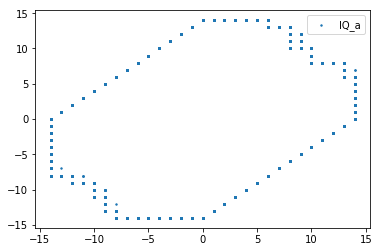

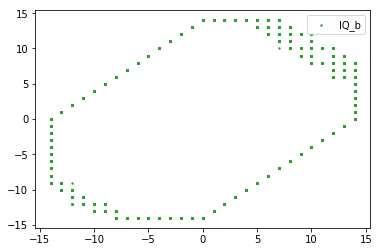

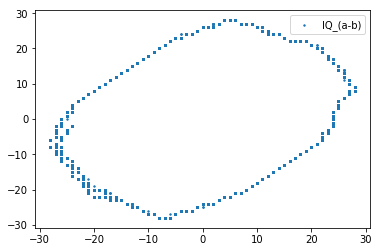

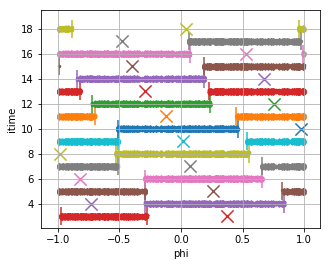

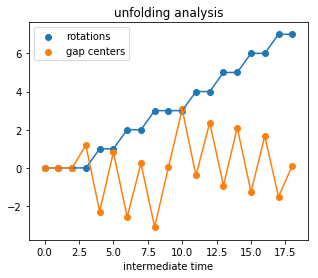

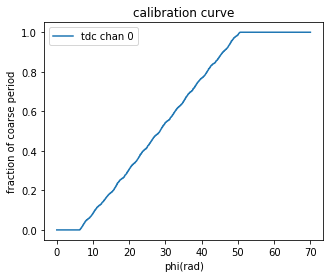

{'avg_zeros': 35.034580419580422,
 'avg_ones': 32.521308806771934,
 'avg_period': 67.555889226352349,
 'avg_duty': 0.48139857500515221,
 'rotations': array([ 0.,  0.,  0.,  0.,  1.,  1.,  2.,  2.,  3.,  3.,  3.,  4.,  4.,
         5.,  5.,  6.,  6.,  7.,  7.]),
 'gap_centers': array([ 0.        ,  0.        ,  0.        ,  1.18401413, -2.28799319,
         0.8199963 , -2.56629285,  0.23355991, -3.09388319,  0.04218815,
         3.0662747 , -0.39225543,  2.37078888, -0.92566656,  2.11300901,
        -1.25757373,  1.66420641, -1.51366916,  0.12140942]),
 'calib_bins': array([  0.00000000e+00,   1.00000000e-02,   2.00000000e-02, ...,
          6.99700000e+01,   6.99800000e+01,   6.99900000e+01]),
 'box_diagram': array([ 0.,  0.,  0., ...,  0.,  0.,  0.]),
 'calib_curve': array([ 0.,  0.,  0., ...,  1.,  1.,  1.]),
 'hits':            t_lead  trig_num
 0        0.000002   6764176
 64       0.000002   6764177
 128      0.000002   6764178
 192      0.000002   6764179
 256      0.000002   676

In [62]:
process_channel(df,0,plot=True)


In [61]:
for i in active_channels:
    #print("ch {} data_length = {}".format(i,len(ch_data[i]["hits"]["t_lead"])))
    print("ch {} period = {:3.3f}, duty = {:3.3f}".format(i,ch_data[i]["avg_period"],ch_data[i]["avg_duty"]))
          
          

ch 0 period = 67.556, duty = 0.481
ch 1 period = 70.720, duty = 0.486
ch 2 period = 68.590, duty = 0.480
ch 3 period = 69.744, duty = 0.487
ch 4 period = 69.808, duty = 0.484
ch 5 period = 72.816, duty = 0.473
ch 6 period = 66.736, duty = 0.487
ch 7 period = 71.365, duty = 0.479
ch 8 period = 69.160, duty = 0.480
ch 9 period = 70.775, duty = 0.484
ch 10 period = 67.043, duty = 0.481
ch 11 period = 69.033, duty = 0.487
ch 12 period = 68.782, duty = 0.477
ch 13 period = 72.355, duty = 0.487
ch 14 period = 68.647, duty = 0.481
ch 15 period = 70.619, duty = 0.480
ch 16 period = 67.420, duty = 0.484
ch 17 period = 69.653, duty = 0.488
ch 18 period = 67.933, duty = 0.484
ch 19 period = 70.307, duty = 0.481
ch 20 period = 68.794, duty = 0.477
ch 21 period = 68.199, duty = 0.492
ch 22 period = 69.567, duty = 0.486
ch 23 period = 71.956, duty = 0.479
ch 24 period = 70.500, duty = 0.474
ch 25 period = 69.171, duty = 0.473
ch 26 period = 67.462, duty = 0.483
ch 27 period = 71.904, duty = 0.478
ch

In [45]:
ch_data[0]

{'avg_zeros': 35.017546209482987,
 'avg_ones': 32.503929024081117,
 'rotations': array([ 0.,  0.,  0.,  0.,  1.,  1.,  2.,  2.,  3.,  3.,  3.,  4.,  4.,
         5.,  5.,  6.,  6.,  7.,  7.]),
 'gap_centers': array([ 0.        ,  0.        ,  0.        ,  1.18401413, -2.28799319,
         0.8199963 , -2.56629285,  0.23355991, -3.1178011 ,  0.04218815,
         3.0662747 , -0.38534667,  2.37078888, -0.92566656,  2.11300901,
        -1.29678437,  1.64950476, -1.53427604,  0.10444465]),
 'calib_bins': array([  0.00000000e+00,   1.00000000e-02,   2.00000000e-02, ...,
          6.99700000e+01,   6.99800000e+01,   6.99900000e+01]),
 'box_diagram': array([ 0.,  0.,  0., ...,  0.,  0.,  0.]),
 'calib_curve': array([ 0.,  0.,  0., ...,  1.,  1.,  1.]),
 'hits':           t_lead  trig_num
 0       0.000002   6764176
 64      0.000002   6764177
 128     0.000002   6764178
 192     0.000002   6764179
 256     0.000002   6764180
 320     0.000002   6764181
 384     0.000002   6764182
 448     0.000

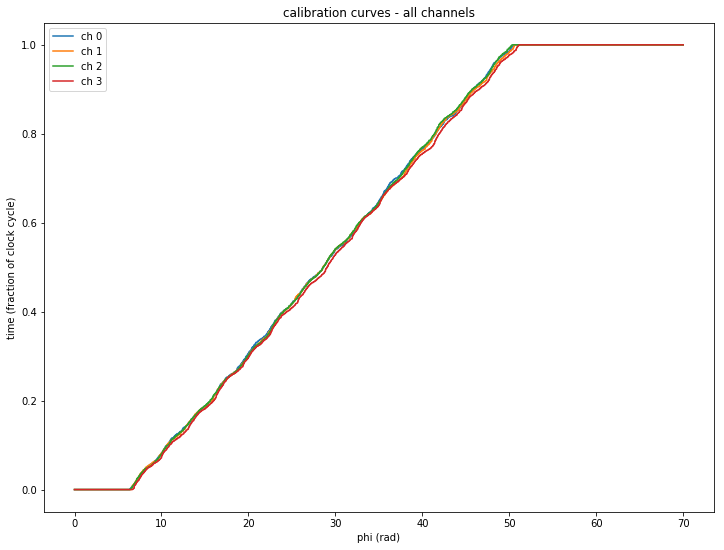

In [10]:
big_figure()

for key in ch_data.keys():
    d = ch_data[key]
    x = d["calib_bins"]
    y = d["calib_curve"]
    plt.plot(x,y,label="ch "+str(key))
    
plt.title("calibration curves - all channels")
plt.xlabel("phi (rad)")
plt.ylabel("time (fraction of clock cycle)")
plt.legend()
plt.show()


ch 0 vs ch 0
standard deviation: 0.000ps
mean diff: 0.000ns
ch 0 vs ch 1
standard deviation: 8.067ps
mean diff: -0.659ns
ch 0 vs ch 2
standard deviation: 7.715ps
mean diff: -0.562ns
ch 0 vs ch 3
standard deviation: 7.893ps
mean diff: 0.528ns
ch 0 vs ch 4
standard deviation: 7.710ps
mean diff: 1.221ns
ch 0 vs ch 5
standard deviation: 7.838ps
mean diff: 1.024ns
ch 0 vs ch 6
standard deviation: 7.823ps
mean diff: 0.455ns
ch 0 vs ch 7
standard deviation: 8.022ps
mean diff: 0.904ns
ch 0 vs ch 32
standard deviation: 10.532ps
mean diff: -1.225ns
ch 0 vs ch 33
standard deviation: 8.442ps
mean diff: -0.457ns
ch 0 vs ch 34
standard deviation: 8.257ps
mean diff: -0.706ns
ch 0 vs ch 35
standard deviation: 8.115ps
mean diff: -0.202ns
ch 0 vs ch 36
standard deviation: 8.481ps
mean diff: -0.712ns
ch 0 vs ch 37
standard deviation: 7.993ps
mean diff: -0.418ns
ch 0 vs ch 38
standard deviation: 8.408ps
mean diff: -0.810ns
ch 0 vs ch 39
standard deviation: 8.290ps
mean diff: -0.414ns
ch 0 vs ch 64
standar

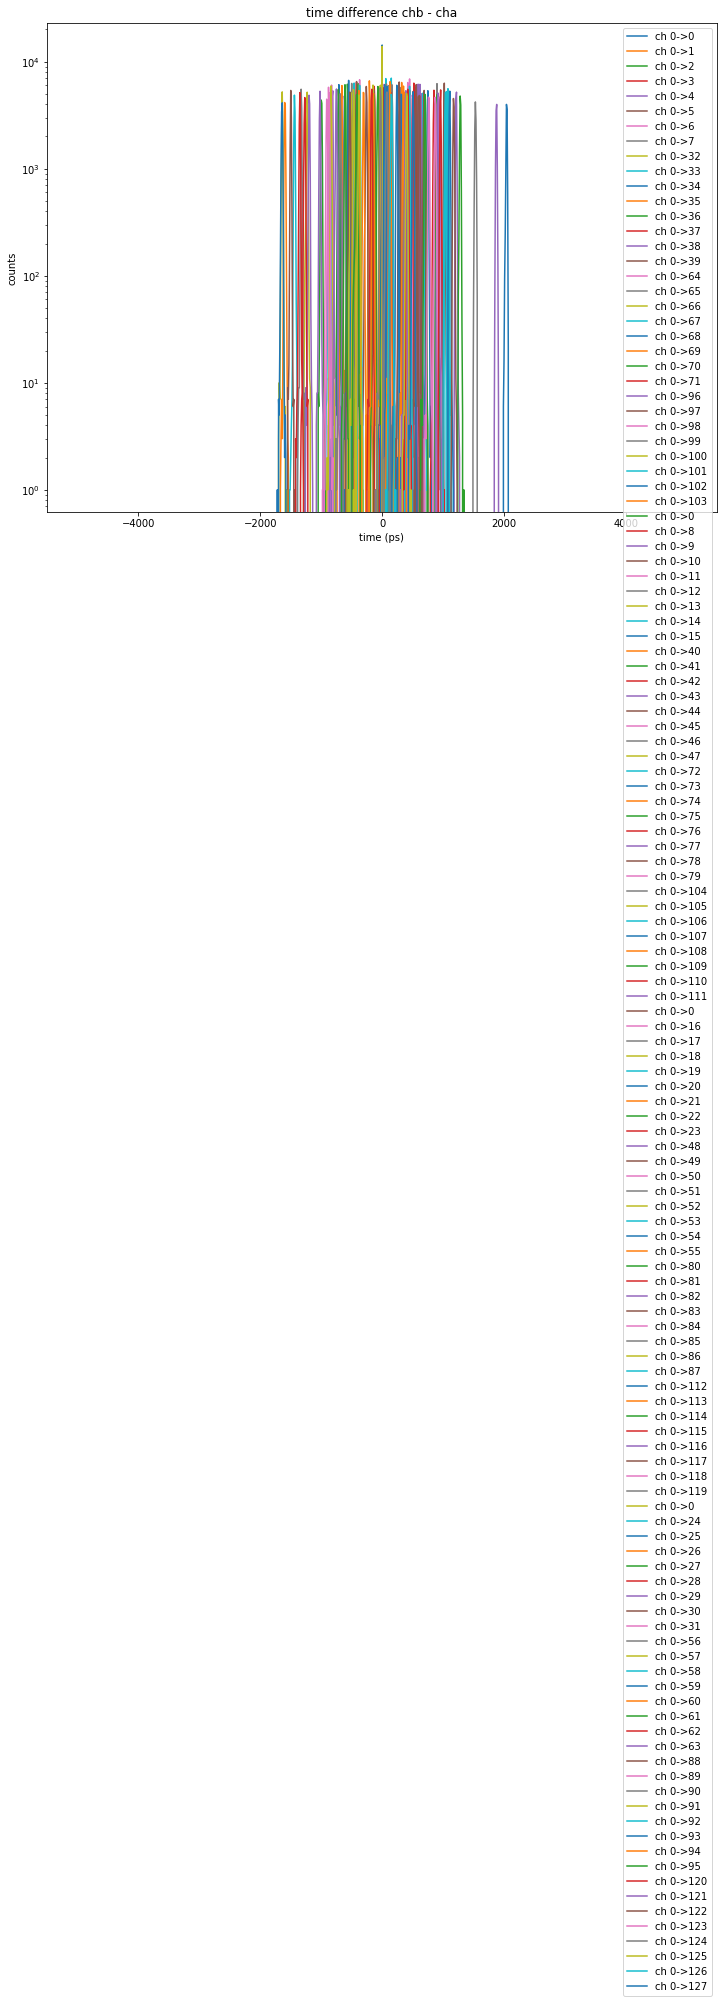

In [21]:

na = 0

L = -5e-9
R = 5e-9

ch_ch_dev     = np.array([0.0]*128)
MC_std_vs_self = np.array([0.0]*128) 


# loop over data files
for df in [df1, df2, df3, df4]:


    ch_data = {}
    
    active_channels = df["chan"].unique()
    
    for i in active_channels:
        ch_data[i] =  process_channel(df,i,plot=False)
    
    
    
    
    for nb in active_channels:
    
        
        mdf = pd.merge(
            ch_data[na]["hits"],
            ch_data[nb]["hits"],
            on="trig_num",
            how="inner",
            suffixes=("_1", "_2")
        )
    
        mdf["t_diff"] = mdf["t_lead_2"] - mdf["t_lead_1"]
        
        
        sel = mdf[ (mdf["t_diff"] > L) & (mdf["t_diff"] < R)]
        
        x,y = fast_hist(sel["t_diff"] *1e12,L*1e12,R*1e12,10)
        plt.plot(x,y,label="ch {}->{}".format(na,nb))
        plt.yscale("log")
        std = np.std(sel["t_diff"])
        if(1):
            print("ch {} vs ch {}".format(na,nb))
            print("standard deviation: {:3.3f}ps".format(std*1e12))
            print("mean diff: {:3.3f}ns".format(np.mean(sel["t_diff"])*1e9))
        
        ch_ch_dev[nb] = std
        
        MC_std_vs_self[nb]  = sim_stddev_MC(nb,nb,1000,rand_shift=True)
    
    
    


#plt.hist(tdiff*1e12)
plt.title("time difference chb - cha")
plt.legend()
plt.ylabel("counts")
plt.xlabel("time (ps)")
plt.show()





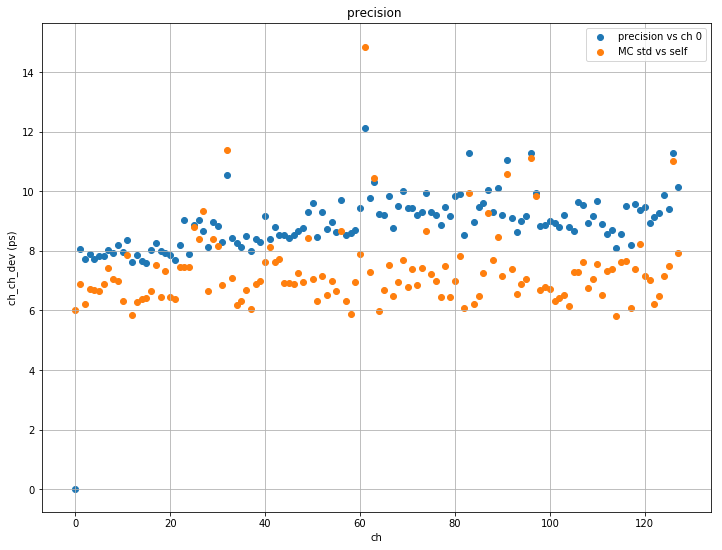

In [23]:
x = np.array(range(0,len(ch_ch_dev)))
#plt.plot(x,ch_ch_dev*1e12)
plt.scatter(x,ch_ch_dev*1e12,label="precision vs ch {}".format(na))

plt.scatter(x,MC_std_vs_self*1e12,label="MC std vs self")

#new = ch_ch_dev.copy()
#plt.scatter(x,new*1e12,label="new".format(na))

plt.xlabel("ch")
plt.ylabel("ch_ch_dev (ps)")
#plt.xlim(60,100)
plt.grid(True)
plt.title("precision ")
plt.legend()
plt.show()


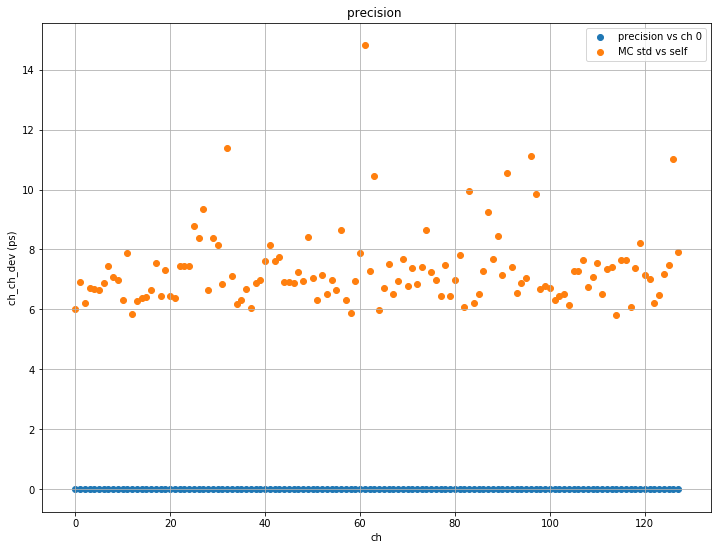

In [24]:
x = np.array(range(0,len(ch_ch_dev)))
#plt.plot(x,ch_ch_dev*1e12)
plt.scatter(x,0*ch_ch_dev*1e12,label="precision vs ch {}".format(na))

plt.scatter(x,MC_std_vs_self*1e12,label="MC std vs self")

#new = ch_ch_dev.copy()
#plt.scatter(x,new*1e12,label="new".format(na))

plt.xlabel("ch")
plt.ylabel("ch_ch_dev (ps)")
#plt.xlim(60,100)
plt.grid(True)
plt.title("precision ")
plt.legend()
plt.show()


In [ ]:
x = np.array(range(0,len(ch_ch_dev)))
#plt.plot(x,ch_ch_dev*1e12)


#plt.scatter(x,ch_ch_dev*1e12,label="precision vs ch 64")

#plt.scatter(x,avg_bin_sizes*1e12,label="avg_bin_size")

#TDC bin error is not 1/sqrt(12) but 1/sqrt(3) - because we do not round

#plt.scatter(x,prec_vs_na*1e12,label="gauss ch vs ch 64")

#plt.scatter(x,MC_std_vs_na*1e12,label="MC std vs ch{}".format(na))
plt.scatter(x,MC_std_vs_self*1e12,label="MC std vs self")
#plt.scatter(x,MC_std_vs_ideal*1e12,label="MC std vs ideal")
plt.scatter(x,MC_std_vs_ideal*1e12*np.sqrt(2),label="MC std vs ideal * sqrt(2)")
#plt.scatter(x,avg_bin_sizes/np.sqrt(3)*1e12,label="avg_bin_size/sqrt3")
#plt.scatter(x,avg_bin_sizes/np.sqrt(12)*1e12,label="avg_bin_size/sqrt12")

plt.xlabel("ch")
plt.ylabel("ch_ch_dev (ps)")
#plt.xlim(60,100)
plt.grid(True)
plt.title("precision ")
plt.legend()
plt.show()


In [ ]:
ccurve = ch_data[64]["calib_curve"]
box    = ch_data[64]["box_diagram"]
csum   = np.cumsum(box)

#plt.plot(ccurve[1000:1200])
plt.plot(csum[1000:1200])

box_cor = rotate_array(box.copy(),-1)



last_val = box_cor[len(box_cor)-1]
for i in range(len(box_cor)-2,0-1,-1):
    if (box_cor[i] == 0):
        box_cor[i] = last_val
    else:
        last_val = box_cor[i]
        
        
#plt.plot(10*box[1000:1200])
#plt.plot(10*box_cor[1000:1200])
plt.plot(csum[1000:1200]+.5*box_cor[1000:1200])

#plt.plot

     